# Exploración inicial de datos — competencia_01

**Objetivo del análisis:** evaluar si `competencia_01.csv` tiene la calidad, integridad y señal necesarias para justificar la inversión en un modelo predictivo de baja (churn) de clientes, y dejar identificados los riesgos de datos que el equipo de modelado debe resolver antes de entrenar.

**Alcance:** 6 períodos mensuales consecutivos (`202103`–`202108`), ~170K clientes, 153 variables de tenencia de productos y comportamiento transaccional, más la variable objetivo `clase_ternaria` (`CONTINUA` / `BAJA+1` / `BAJA+2`).

**Metodología:** perfilado con DuckDB directamente sobre el CSV (evita cargar ~1GB en memoria para cada chequeo); solo se materializan en pandas los resultados agregados o muestras necesarias para graficar.

In [3]:
import duckdb
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

dataset_path = '../data/'
dataset_file = 'competencia_01.csv'

con = duckdb.connect()
con.sql(f"create or replace view c01 as select * from read_csv_auto('{dataset_path + dataset_file}')")

## 1. Estructura y grano de los datos

Antes de analizar cualquier variable, hay que confirmar que el grano de la tabla es el que se espera (cliente-mes) y que no hay registros duplicados que puedan inflar o sesgar cualquier agregación posterior.

In [4]:
con.sql("""
    select
        count(*) as registros
        , count(distinct numero_de_cliente) as clientes_unicos
        , count(distinct foto_mes) as periodos
        , (select count(*) from (describe select * from c01)) as columnas
    from c01
""").df()

In [5]:
con.sql("""
    select numero_de_cliente, foto_mes, count(*) as repeticiones
    from c01
    group by numero_de_cliente, foto_mes
    having count(*) > 1
""").df()

In [7]:
con.sql("""
    select master_fvencimiento as fvencimiento
    from c01
""").df()

In [6]:
con.sql("""
    select foto_mes, count(*) as clientes
    from c01
    group by foto_mes
    order by foto_mes
""").df()

**Resultado:** el grano `(numero_de_cliente, foto_mes)` es único, sin duplicados. La base crece de forma estable (~1.1% acumulado entre marzo y agosto), sin saltos que sugieran un problema de carga en algún mes puntual. La tabla es confiable para agregaciones directas, sin necesidad de deduplicar.

## 2. Calidad de datos

### 2.1 Completitud de la variable objetivo

In [16]:
con.sql("""
    select
        foto_mes
        , count(*) as registros
        , sum(case when clase_ternaria is null then 1 else 0 end) as sin_clase
    from c01
    group by foto_mes
    order by foto_mes
""").df()

**Resultado:** los dos últimos períodos (`202107` parcialmente, `202108` en su totalidad) no tienen `clase_ternaria` definida — es estructural, no un error de carga: para saber si un cliente se da de baja hace falta observar 1 o 2 meses hacia adelante, y esos meses todavía no existen en el dataset. **Implicancia para el equipo de modelado:** ese 33% de las filas debe reservarse como conjunto de aplicación/scoring, nunca usarse para entrenar ni para medir performance del modelo.

### 2.2 Valores faltantes

In [17]:
columnas = con.sql("describe select * from c01").df()['column_name'].tolist()
columnas = [c for c in columnas if c not in ('numero_de_cliente', 'foto_mes')]

expresiones = ', '.join([f'sum(case when "{c}" is null then 1 else 0 end) as "{c}"' for c in columnas])
nulos = con.sql(f"select {expresiones} from c01").df().T
nulos.columns = ['cantidad_nulos']

total_registros = con.sql("select count(*) from c01").fetchone()[0]
nulos['pct_nulos'] = (nulos['cantidad_nulos'] / total_registros * 100).round(2)
nulos.sort_values('pct_nulos', ascending=False, inplace=True)

nulos[nulos['pct_nulos'] > 0].head(15)

In [18]:
con.sql("""
    select
        ctarjeta_master
        , count(*) as clientes
        , sum(case when Master_status is null then 1 else 0 end) as master_status_nulo
    from c01
    group by ctarjeta_master
    order by ctarjeta_master
""").df()

**Resultado:** los nulos concentrados en `Master_*` y `Visa_*` (entre 5% y 99% según la columna) no son datos faltantes en el sentido tradicional: coinciden exactamente con clientes que no poseen esa tarjeta (`ctarjeta_master = 0` ⇒ 100% de `Master_status` nulo). **Implicancia:** no corresponde imputar con media/mediana — hay que codificar explícitamente "no posee el producto" (constante o flag dedicado), porque estadísticamente es información, no ausencia de información. Aplica el mismo criterio a toda la familia `Master_*`/`Visa_*`.

### 2.3 Valores extremos en variables monetarias

In [19]:
con.sql("""
    select
        min(mcuentas_saldo) as p0
        , quantile_cont(mcuentas_saldo, 0.5) as p50
        , quantile_cont(mcuentas_saldo, 0.99) as p99
        , quantile_cont(mcuentas_saldo, 0.999) as p999
        , max(mcuentas_saldo) as p100
        , sum(case when mcuentas_saldo > 10000000 then 1 else 0 end) as clientes_saldo_mayor_10M
    from c01
""").df()

**Resultado:** `mcuentas_saldo` tiene una cola derecha muy pesada — mediana ~39K pero máximo de ~328M, con 1.813 registros (~0.18%) por encima de 10M. Es esperable en datos bancarios (probable segmento de banca privada/empresas mezclado con retail), pero sin tratamiento va a dominar cualquier modelo basado en distancias o splits sensibles a escala. **Recomendación:** winsorizar/cappear o usar transformaciones robustas a la escala, y confirmar con el negocio si esos registros son legítimos o corresponden a un segmento que debería excluirse del scope del modelo.

In [20]:
con.sql("select min(cproductos) as min_productos, max(cproductos) as max_productos from c01").df()

**Resultado:** el mínimo de `cproductos` es 3 (nunca 0, 1 o 2). Esto sugiere que la población del dataset ya viene filtrada a clientes con relación comercial mínima establecida (no es la base completa de la entidad). **Punto a validar con el área que provee los datos**, porque cambia cómo se interpreta cualquier conclusión: este análisis describe la fuga *dentro* de la base de clientes ya vinculados, no la captación ni la adopción inicial de productos.

## 3. La variable objetivo: magnitud del problema de negocio

In [21]:
balance = con.sql("""
    select clase_ternaria, count(*) as registros
    from c01
    where clase_ternaria is not null
    group by clase_ternaria
""").df()

balance['pct'] = (balance['registros'] / balance['registros'].sum() * 100).round(3)
balance

**Resultado:** la baja es un evento raro — `BAJA+2` (el evento que interesa detectar con anticipación) representa ~0.62% de los registros con clase conocida, `BAJA+1` ~0.78%. Esto tiene dos consecuencias directas para el proyecto:

* **Métricas de evaluación:** *accuracy* es inútil (un modelo que nunca predice baja ya acierta >99%). Hay que evaluar con métricas de ranking (AUC, ganancia acumulada por punto de corte) y no con métricas de clasificación binaria estándar.
* **Económicamente, igual vale la pena.** Usando los parámetros de campaña ya definidos para este proyecto (`ganancia_acierto = $1.072.500` por baja detectada y contactada a tiempo, `costo_estimulo = $27.500` por cada contacto, acierte o no), el punto de equilibrio de precisión se calcula así:

In [22]:
ganancia_acierto = 1_072_500
costo_estimulo = 27_500

precision_equilibrio = costo_estimulo / (ganancia_acierto + costo_estimulo)
tasa_base_baja2 = balance.set_index('clase_ternaria').loc['BAJA+2', 'pct'] / 100

pd.DataFrame({
    'métrica': ['Precisión de equilibrio', 'Tasa base de BAJA+2', 'Lift mínimo necesario'],
    'valor': [f'{precision_equilibrio:.2%}', f'{tasa_base_baja2:.2%}', f'{precision_equilibrio/tasa_base_baja2:.1f}x']
})

**Resultado:** con una precisión de apenas ~2.5% ya se recupera el costo del estímulo — un modelo necesita un *lift* de solo ~4x sobre targeting aleatorio para que la campaña sea rentable. Es una barrera baja dado que, como se muestra más abajo, ya en esta primera exploración aparece señal fuerte y explicable. **Conclusión de negocio: el proyecto está económicamente justificado incluso con un modelo modesto.**

## 4. Perfil de los clientes que se dan de baja

In [23]:
con.sql("""
    select
        clase_ternaria
        , avg(cliente_edad) as edad_media
        , avg(cliente_antiguedad) as antiguedad_media_meses
        , avg(cproductos) as productos_media
    from c01
    where clase_ternaria is not null
    group by clase_ternaria
""").df()

**Resultado:**

* **Edad:** prácticamente igual entre clases (~47 años) — no es una variable discriminante, no priorizar esfuerzo de ingeniería de features acá.
* **Antigüedad y cross-sell sí discriminan:** los clientes que se dan de baja tienen en promedio ~22-24 meses menos de antigüedad (≈110 vs. 135 meses) y casi un producto menos contratado (~6.2-6.4 vs. 7.55) que los que continúan. Es consistente con un patrón conocido en retail banking: los clientes menos "anclados" (poca antigüedad, poca variedad de productos) tienen menor costo de cambio y se van más fácil.

## 5. Estabilidad temporal de las variables

Antes de confiarle una variable a un modelo que va a scorear meses futuros, hay que descartar que algún cambio de comportamiento observado sea en realidad un quiebre de captura de datos (por ejemplo, un canal que se empieza a medir a mitad de año) y no un cambio real del cliente.

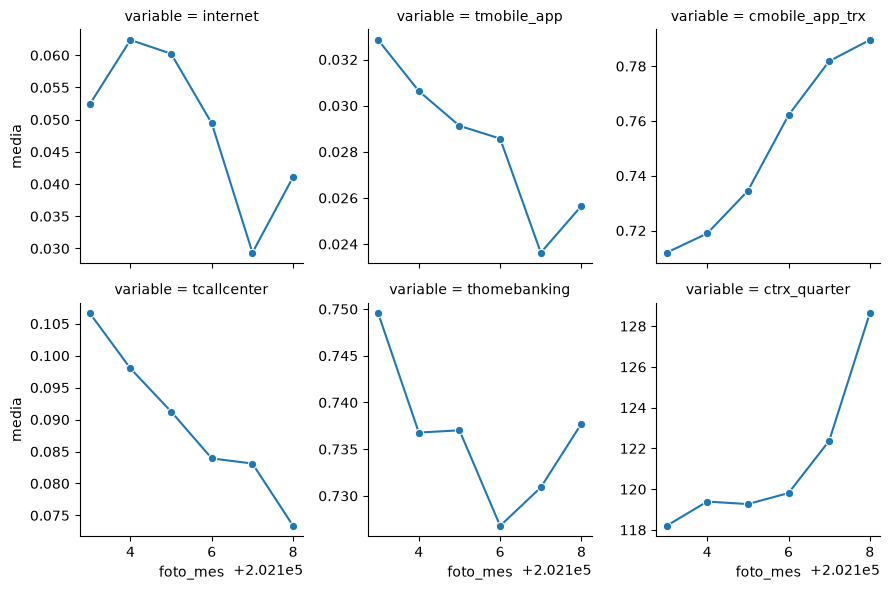

In [24]:
canales = ['internet', 'tmobile_app', 'cmobile_app_trx', 'tcallcenter', 'thomebanking', 'ctrx_quarter']

evolucion = con.sql(f"""
    select foto_mes, {', '.join(f'avg({c}) as {c}' for c in canales)}
    from c01
    group by foto_mes
    order by foto_mes
""").df()

evolucion_long = evolucion.melt(id_vars='foto_mes', var_name='variable', value_name='media')

g = sns.FacetGrid(evolucion_long, col='variable', col_wrap=3, sharey=False, height=3)
g.map(sns.lineplot, 'foto_mes', 'media', marker='o')
plt.show()

**Resultado:** ningún canal muestra un salto abrupto (que delataría un problema de captura). La única tendencia notable es `ctrx_quarter`, que crece de forma sostenida a lo largo del período (~9% entre marzo y agosto) — probablemente crecimiento genuino de actividad, pero conviene monitorearlo en producción: si un modelo se entrena con los niveles de actividad de marzo y se aplica meses después, un corrimiento de escala de este tipo puede degradar la calibración de las probabilidades sin que el modelo esté "roto".

## 6. Señal temprana: la actividad cae antes de la baja

El hallazgo más accionable de esta exploración: comparando la actividad transaccional del mes actual contra la de 1 y 2 meses atrás (mismo cliente), separado por clase.

In [25]:
tendencia = con.sql("""
    with con_lags as (
        select
            clase_ternaria
            , ctrx_quarter
            , lag(ctrx_quarter, 1) over (partition by numero_de_cliente order by foto_mes) as ctrx_quarter_t_menos_1
            , lag(ctrx_quarter, 2) over (partition by numero_de_cliente order by foto_mes) as ctrx_quarter_t_menos_2
        from c01
    )
    select
        clase_ternaria
        , avg(ctrx_quarter) as ctrx_quarter_t
        , avg(ctrx_quarter_t_menos_1) as ctrx_quarter_t_menos_1
        , avg(ctrx_quarter_t_menos_2) as ctrx_quarter_t_menos_2
    from con_lags
    where clase_ternaria is not null
    group by clase_ternaria
""").df()

tendencia

**Resultado:** los clientes que terminan dándose de baja ya operaban con muchísima menos actividad que los que continúan — no solo en el mes de la baja, sino **1 y 2 meses antes** (`ctrx_quarter` ronda 40-47 para `BAJA+1`/`BAJA+2` en los meses previos, contra ~120 para `CONTINUA`, de forma consistente en los tres momentos). Es una señal fuerte, estable en el tiempo y fácil de explicar al negocio. **Recomendación directa para el equipo de modelado:** priorizar features de tendencia (deltas y ratios de actividad mes a mes) sobre variables de nivel — es probable que aporten más que agregar más variables de foto instantánea.

## Conclusiones y recomendaciones

*Resumen para presentar al negocio / a quien decide si se sigue invirtiendo en este proyecto.*

**El dataset es apto para modelar, con algunos ajustes previos:**

1. **Integridad:** sin duplicados, grano cliente-mes consistente, crecimiento de base estable mes a mes. No hay señales de un problema de carga o de pipeline.
2. **El objetivo está bien definido pero incompleto en el borde temporal:** el 33% de las filas (los 2 últimos meses) no tiene clase por construcción — deben separarse como conjunto de aplicación, no de entrenamiento.
3. **La baja es un evento raro (~0.6-0.8% mensual)**, pero la economía de la campaña ya definida hace que el proyecto sea rentable con una precisión de modelo tan baja como ~2.5% — el umbral de "vale la pena" es bajo y alcanzable.
4. **Ya en esta primera pasada aparece señal clara, estable y explicable:** la caída de actividad transaccional en los 1-2 meses previos a la baja es el indicador más fuerte encontrado; antigüedad y cantidad de productos contratados también discriminan; la edad no aporta.
5. **No se detectaron quiebres de captura de datos graves**, aunque `ctrx_quarter` muestra una tendencia creciente que conviene vigilar en producción por su efecto en la calibración del modelo.

**Riesgos de calidad de datos a resolver antes de entrenar (no bloquean el proyecto, pero si se ignoran van a sesgar el modelo):**

* Los nulos masivos en variables `Master_*`/`Visa_*` son estructurales (el cliente no tiene esa tarjeta) y deben codificarse como tal, no imputarse estadísticamente.
* Hay una cola de valores extremos en variables de saldo (`mcuentas_saldo` y probablemente análogas) que requiere capping o transformación antes de usarse en modelos sensibles a escala; conviene confirmar con negocio si esos ~1.800 registros corresponden a un segmento a tratar aparte.
* `cproductos` nunca es menor a 3 — se debe confirmar con el área de datos si esta tabla ya viene pre-filtrada a una subpoblación de clientes, porque cambia el alcance de cualquier conclusión.

**Próximos pasos propuestos:**

1. Confirmar con negocio el alcance poblacional (punto anterior) y el tratamiento de outliers de saldo.
2. Construir features de tendencia (deltas/ratios de 1-2-3 meses) sobre actividad y rentabilidad, dado que es la señal más fuerte encontrada.
3. Definir el esquema de validación respetando el orden temporal (entrenar en meses tempranos, validar en los últimos con clase completa) — no usar validación cruzada aleatoria en un problema con esta dinámica temporal.
4. Fijar la métrica de éxito del modelo en términos de ganancia económica esperada (curva de ganancia acumulada por punto de corte), no en accuracy ni F1 a secas.